## Output Analysis V2
Similar to the original notebook, but focuses on plotting different model runs side by side.

In [16]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from model_datasets.forcing import LM4Forcing
from model_datasets.output import LM4ModelOutput
from model_datasets.snotel import PNNLSnotel

from pathlib import Path
from dotenv import load_dotenv
load_dotenv(Path.cwd().parents[1] / ".env")

True

In [15]:
# Run settings
site = 'Cumbres Trestle'
model_runs = ['s01011010_gbc_v0005','s01011010_ghelaps_v0008']
experiment_names = ['BRDF','LAPS']
forcing_file = '01011010_v0.10.1'

#### Load Forcing

In [3]:
forcing_str, forcing_version = forcing_file.split('_')
forcing_version = forcing_version[1:]

forcing = LM4Forcing(site=site, forcing_string=forcing_str, version=forcing_version, spinup=False)

In [4]:
forcing_vars = forcing.get_variables()
forcing_vars.head()

,dimensions,long_name,units
Tair,"(time, latitude, longitude)",Near-surface air Temperature,K
Qair,"(time, latitude, longitude)",Near-surface specific humidity,kg/kg
Psurf,"(time, latitude, longitude)",Surface Pressure,Pa
Rainf,"(time, latitude, longitude)",Rainfall rate,kg/m2/s
Snowf,"(time, latitude, longitude)",Snowfall rate,kg/m2/s


### Load SNOTEL

In [5]:
import os

In [6]:
snotel = PNNLSnotel(site, os.environ['SNOTEL_PATH'])
snotel.load_data()
snotel.data.head()

,T_max_C,T_min_C,T_avg_C,precip_mm,swe_mm
Date,,,,,
1980-08-06 00:00:00-06:00,NaN,NaN,NaN,0.00,0.0
1980-08-07 00:00:00-06:00,NaN,NaN,NaN,2.54,0.0
1980-08-08 00:00:00-06:00,NaN,NaN,NaN,0.00,0.0
1980-08-09 00:00:00-06:00,NaN,NaN,NaN,0.00,0.0
1980-08-10 00:00:00-06:00,NaN,NaN,NaN,0.00,0.0


In [7]:
snotel_data = snotel.data

# Remove timezone from index
snotel_data.index = snotel_data.index.tz_localize(None)


#### Load Models

In [12]:
models = []
for model_str in model_runs:
    model_forcing, namelist, version = model_str.split('_')
    version = version[1:]
    model = LM4ModelOutput(site=site, forcing_string=forcing_str, namelist=namelist, version=version, spinup=False)
    models.append(model.get_data(['snow','snow_depth'],'land_daily'))

### Data Processing

In [ ]:
# Extract forcing data

# Forcing time comes back as datetime64[ns], while model/SNOTEL data is datetime64[us].
# Align the resolution so matplotlib doesn't have to swap axis converters mid-plot.
Tair = forcing.get_data('Tair')
Tair.index = Tair.index.as_unit('us')
Tair = Tair - 273.15  # Convert from Kelvin to Celsius
Tair_max = Tair.resample('D').max()
Tair_min = Tair.resample('D').min()

# Extract precipitation and recombine
snowfall = forcing.get_data('Snowf')
snowfall.index = snowfall.index.as_unit('us')
rainfall = forcing.get_data('Rainf')
rainfall.index = rainfall.index.as_unit('us')

precipdf = pd.DataFrame({'snowf':snowfall,'rainf':rainfall})
precipdf['combined'] = (precipdf['snowf'] + precipdf['rainf'])*3600 #Convert to hourly total kg/m2/s

precip_daily = precipdf['combined'].resample('1D').sum()

### Plots

In [13]:
# Get range of dates for plotting
start_date = models[0].index[0]
end_date = models[0].index[-1]

In [19]:
# Custom range
start_date = '2009-10-01'
end_date = '2020-06-01'

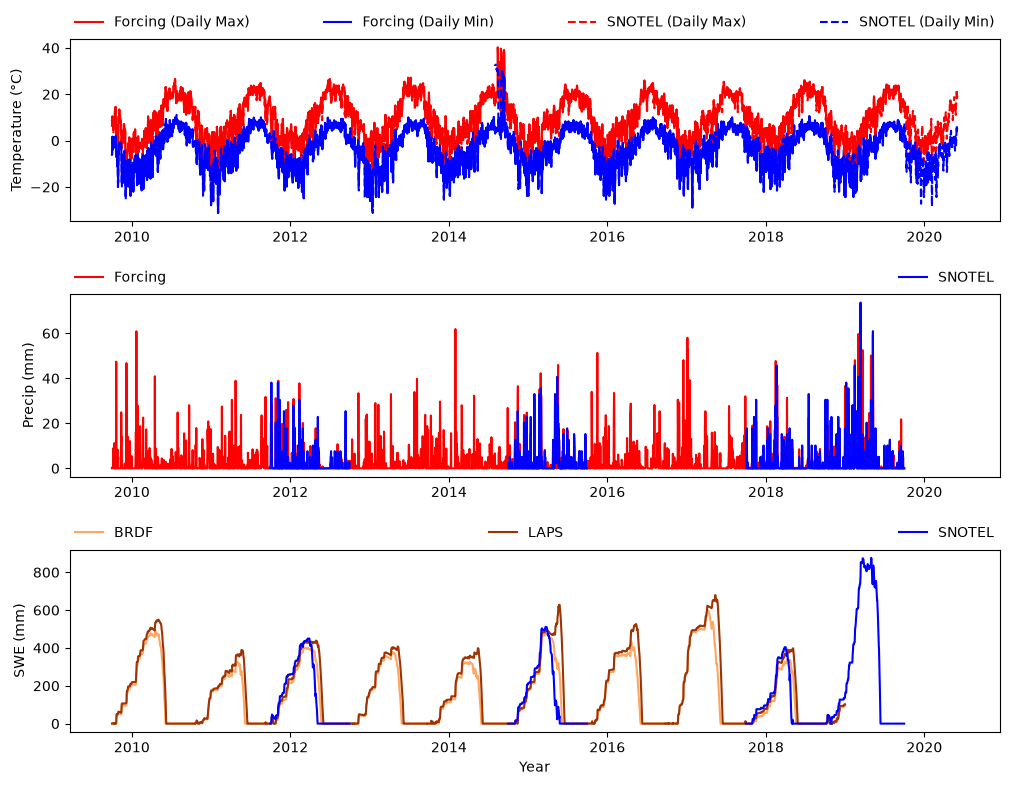

In [23]:
# Plot snow

def line(ax, series, **kwargs):
    # Series.plot() picks its datetime converter per call, which can conflict with a sharex
    # neighbor's converter and trigger a UserWarning; plotting the raw arrays avoids that.
    ax.plot(series.index.values, series.values, **kwargs)

fig, ax = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

line(ax[0], Tair_max.loc[start_date:end_date], label='Forcing (Daily Max)', color='red')
line(ax[0], Tair_min.loc[start_date:end_date], label='Forcing (Daily Min)', color='blue')
line(ax[0], snotel_data.loc[start_date:end_date, 'T_max_C'], label='SNOTEL (Daily Max)', color='red', linestyle='--')
line(ax[0], snotel_data.loc[start_date:end_date, 'T_min_C'], label='SNOTEL (Daily Min)', color='blue', linestyle='--')

line(ax[1], precip_daily.loc[start_date:end_date], label='Forcing', color='red')
line(ax[1], snotel_data.loc[start_date:end_date, 'precip_mm'], label='SNOTEL', color='blue')

model_colors = plt.cm.Oranges(np.linspace(0.4, 0.9, len(models)))
for model_data, name, color in zip(models, experiment_names, model_colors):
    line(ax[2], model_data.loc[start_date:end_date, 'snow'], label=name, color=color)
line(ax[2], snotel_data.loc[start_date:end_date, 'swe_mm'], label='SNOTEL', color='blue')

# Add a figure title based on site name
ax[0].set_ylabel('Temperature (°C)')
ax[1].set_ylabel('Precip (mm)')
ax[2].set_ylabel('SWE (mm)')
ax[2].set_xlabel('Year')

# sharex hides tick labels on all but the bottom subplot by default; show them on all three
ax[0].tick_params(axis='x', labelbottom=True)
ax[1].tick_params(axis='x', labelbottom=True)

# Horizontal legend strips above each subplot, entirely outside the axes so they
# never overlap the data no matter where the lines fall.
legend_kwargs = dict(loc='lower left', bbox_to_anchor=(0, 1.02, 1, 0.1), mode='expand', borderaxespad=0, frameon=False)
ax[0].legend(ncol=4, **legend_kwargs)
ax[1].legend(ncol=2, **legend_kwargs)
ax[2].legend(ncol=len(experiment_names) + 1, **legend_kwargs)

fig.subplots_adjust(hspace=0.4)